In [1]:
import pandas as pd

file_path = r"F:\DXA Internship\Regression Task\Regression Dataset.xlsx"

df = pd.read_excel(file_path)

print(f"Dataset Shape: {df.shape}")

print(f"\nColumn Names:\n{df.columns.tolist()}")

# print(f"\nFirst 5 Rows:\n{df.head()}")

print(f"\nData Types:\n{df.dtypes}")

Dataset Shape: (246, 13)

Column Names:
['ST LE', 'ST HE', 'Bone LE', 'Bone HE', 'A ST LE', 'A ST HE', 'A Bone LE', 'A Bone HE', 'AL', 'Water ', 'I0 ST LE', 'Unnamed: 11', 'I0 ST HE']

Data Types:
ST LE          float64
ST HE          float64
Bone LE        float64
Bone HE        float64
A ST LE        float64
A ST HE        float64
A Bone LE      float64
A Bone HE      float64
AL             float64
Water          float64
I0 ST LE       float64
Unnamed: 11    float64
I0 ST HE       float64
dtype: object


Let's see how many times each aluminium height appears and whether the dataset contains repeated measurements at the same height

In [2]:
al_counts = df['AL'].value_counts().sort_index()

print(f"Number of unique AL Values: ",df["AL"].nunique())
print(f"Minimum AL: ",{df["AL"].min()})
print(f"Maximum AL: ",{df["AL"].max()})

print(f"\nNumber of observations for each AL Value:")
display(al_counts.to_frame(name="Count"))

print(f"\nSummary of repititions counts:")
display(al_counts.describe())

Number of unique AL Values:  14
Minimum AL:  {1.0}
Maximum AL:  {7.5}

Number of observations for each AL Value:


,Count
AL,
1.0,17
1.5,17
2.0,17
2.5,17
3.0,18
3.5,18
4.0,18
4.5,18
5.0,19



Summary of repititions counts:


count    14.000000
mean     17.571429
std       1.342460
min      15.000000
25%      17.000000
50%      18.000000
75%      18.750000
max      19.000000
Name: count, dtype: float64

In [3]:
print("Missing values per column:")
display(df.isnull().sum().to_frame(name="Missing values"))


print("\nExact duplicate rows:", df.duplicated().sum())


model_columns = ["ST LE", "ST HE", "Bone LE", "Bone HE", "AL"]

print(
    "Duplicate rows based on grayscale inputs and AL:",
    df.duplicated(subset=model_columns).sum()
)

Missing values per column:


,Missing values
ST LE,0
ST HE,0
Bone LE,0
Bone HE,0
A ST LE,0
A ST HE,0
A Bone LE,0
A Bone HE,0
AL,0
Water,0



Exact duplicate rows: 0
Duplicate rows based on grayscale inputs and AL: 0


We have no exact duplicate rows, and no repeated combination of the four grayscale inputs and AL. This means the repeated aluminium heights correspond to different grayscale measurements, rather than identical input-target records.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score
)

# Input Features: grayscale values
X = df[["A ST LE", "A ST HE", "A Bone LE", "A Bone HE"]]

# Target: AL
y = df["AL"]

# Slit Ratio: 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size= 0.20, random_state= 42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Input features:", X_train.columns.tolist())


Training samples: 196
Testing samples: 50
Input features: ['A ST LE', 'A ST HE', 'A Bone LE', 'A Bone HE']


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept: ", model.intercept_)

print("\nRegression Coefficients:")
for feature, coef in zip(X_train.columns, model.coef_):
    print(f"{feature}: {coef:.6f}")

Intercept:  -0.5190261785793284

Regression Coefficients:
A ST LE: -1.243371
A ST HE: -26.144965
A Bone LE: -13.338417
A Bone HE: 42.535690


In [6]:
import numpy as np
y_pred = model.predict(X_test)

# Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)*100
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred) * 100,
    "MSE": mean_squared_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2": r2_score(y_test, y_pred)
}

metrics_table = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Value"]
)

print(metrics_table.to_string(index=False, formatters={"Value": "{:.4f}".format}))


  Metric  Value
     MAE 0.1517
MAPE (%) 7.0721
     MSE 0.0416
    RMSE 0.2039
      R2 0.9897


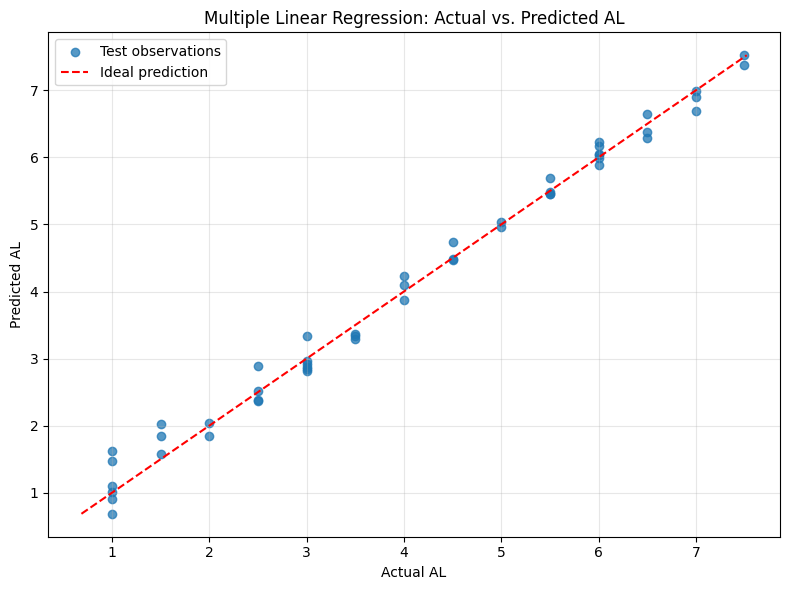

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.75, label="Test observations")

# Ideal predictions lie on this line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal prediction"
)

plt.xlabel("Actual AL")
plt.ylabel("Predicted AL")
plt.title("Multiple Linear Regression: Actual vs. Predicted AL")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Regression with Multi Layer Perceeptron

In [8]:

import random
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score


In [9]:
# Genetic Algorithm settings
POPULATION_SIZE = 8
GENERATIONS = 6
TOURNAMENT_SIZE = 3
MUTATION_RATE = 0.2
CROSSOVER_RATE = 0.8
RANDOM_SEED = 42

# MLP hyperparameter search space
HIDDEN_LAYER_OPTIONS = [
    (16,),
    (32,),
    (64,),
    (32, 16),
    (64, 32)
]

ACTIVATION_OPTIONS = ["relu", "tanh"]

ALPHA_OPTIONS = [0.0001, 0.001, 0.01, 0.1]

LEARNING_RATE_OPTIONS = [0.0001, 0.001, 0.01]

BATCH_SIZE_OPTIONS = [16, 32, 64]

print("GA settings and MLP search space defined successfully.")

GA settings and MLP search space defined successfully.


In [10]:
import pygad

# Each gene represents an index into one of the options below
gene_space = [
    list(range(len(HIDDEN_LAYER_OPTIONS))),  # Architecture
    list(range(len(ACTIVATION_OPTIONS))),    # Activation
    list(range(len(ALPHA_OPTIONS))),         # Alpha
    list(range(len(LEARNING_RATE_OPTIONS))), # Learning rate
    list(range(len(BATCH_SIZE_OPTIONS)))     # Batch size
]

print("PyGAD imported and gene space defined successfully.")

PyGAD imported and gene space defined successfully.


In [11]:
def fitness_func(ga_instance, solution, solution_idx):
    params = {
        "hidden_layer_sizes": HIDDEN_LAYER_OPTIONS[int(solution[0])],
        "activation": ACTIVATION_OPTIONS[int(solution[1])],
        "alpha": ALPHA_OPTIONS[int(solution[2])],
        "learning_rate_init": LEARNING_RATE_OPTIONS[int(solution[3])],
        "batch_size": BATCH_SIZE_OPTIONS[int(solution[4])]
    }

    try:
        mae = evaluate_mlp(params)
        fitness = 1.0 / (1.0 + mae)
        return fitness
    except Exception as e:
        print(f"Candidate evaluation failed: {e}")
        return 0.0


print("PyGAD fitness function defined successfully.")

PyGAD fitness function defined successfully.


In [12]:
ga_instance = pygad.GA(
    num_generations=GENERATIONS,
    num_parents_mating=4,
    fitness_func=fitness_func,
    sol_per_pop=POPULATION_SIZE,
    num_genes=len(gene_space),
    gene_space=gene_space,
    gene_type=int,
    parent_selection_type="tournament",
    K_tournament=TOURNAMENT_SIZE,
    crossover_type="single_point",
    crossover_probability=CROSSOVER_RATE,
    mutation_type="random",
    mutation_probability=MUTATION_RATE,
    keep_elitism=1,
    random_seed=RANDOM_SEED
)

print("PyGAD genetic algorithm configured successfully.")

PyGAD genetic algorithm configured successfully.


In [13]:
def evaluate_mlp(params):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=params["hidden_layer_sizes"],
            activation=params["activation"],
            alpha=params["alpha"],
            learning_rate_init=params["learning_rate_init"],
            batch_size=params["batch_size"],
            solver="adam",
            max_iter=1000,
            early_stopping=False,
            n_iter_no_change=30,
            random_state=RANDOM_SEED
        ))
    ])

    cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=RANDOM_SEED
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    return -scores.mean()


print("evaluate_mlp is now defined.")

evaluate_mlp is now defined.


In [14]:
import time
test_params = {
    "hidden_layer_sizes": (32,),
    "activation": "relu",
    "alpha": 0.001,
    "learning_rate_init": 0.001,
    "batch_size": 32
}

start_time = time.perf_counter()

test_mae = evaluate_mlp(test_params)

elapsed_time = time.perf_counter() - start_time

print(f"3-fold cross-validation MAE: {test_mae:.4f}")
print(f"Evaluation time: {elapsed_time:.2f} seconds")

3-fold cross-validation MAE: 0.1511
Evaluation time: 3.78 seconds


In [15]:
start_time = time.perf_counter()

ga_instance.run()

ga_elapsed_time = time.perf_counter() - start_time

print(f"\nGA optimization completed in {ga_elapsed_time:.2f} seconds")
print(f"GA optimization completed in {ga_elapsed_time / 60:.2f} minutes")


GA optimization completed in 31.85 seconds
GA optimization completed in 0.53 minutes


In [16]:
solution, solution_fitness, solution_idx = ga_instance.best_solution()

best_params = {
    "hidden_layer_sizes": HIDDEN_LAYER_OPTIONS[int(solution[0])],
    "activation": ACTIVATION_OPTIONS[int(solution[1])],
    "alpha": ALPHA_OPTIONS[int(solution[2])],
    "learning_rate_init": LEARNING_RATE_OPTIONS[int(solution[3])],
    "batch_size": BATCH_SIZE_OPTIONS[int(solution[4])]
}

best_cv_mae = (1.0 / solution_fitness) - 1.0

print("Best MLP hyperparameters:")
for param, value in best_params.items():
    print(f"{param}: {value}")

print(f"\nBest 3-fold CV MAE: {best_cv_mae:.4f}")
print(f"GA optimization time: {ga_elapsed_time:.2f} seconds")

Best MLP hyperparameters:
hidden_layer_sizes: (32,)
activation: relu
alpha: 0.0001
learning_rate_init: 0.01
batch_size: 32

Best 3-fold CV MAE: 0.0915
GA optimization time: 31.85 seconds


In [17]:
best_mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=best_params["hidden_layer_sizes"],
        activation=best_params["activation"],
        alpha=best_params["alpha"],
        learning_rate_init=best_params["learning_rate_init"],
        batch_size=best_params["batch_size"],
        solver="adam",
        max_iter=1000,
        early_stopping=False,
        n_iter_no_change=30,
        random_state=RANDOM_SEED
    ))
])

start_time = time.perf_counter()

best_mlp.fit(X_train, y_train)
y_pred_mlp = best_mlp.predict(X_test)

mlp_training_time = time.perf_counter() - start_time

mlp_mae = mean_absolute_error(y_test, y_pred_mlp)
mlp_mse = mean_squared_error(y_test, y_pred_mlp)
mlp_rmse = np.sqrt(mlp_mse)
mlp_r2 = r2_score(y_test, y_pred_mlp)
mlp_mape = mean_absolute_percentage_error(y_test, y_pred_mlp) * 100

print("GA-optimized MLP — Test Results")
print("-" * 40)
print(f"MAE:  {mlp_mae:.4f}")
print(f"MSE:  {mlp_mse:.4f}")
print(f"RMSE: {mlp_rmse:.4f}")
print(f"R²:   {mlp_r2:.4f}")
print(f"MAPE: {mlp_mape:.2f}%")
print(f"Training time: {mlp_training_time:.2f} seconds")

GA-optimized MLP — Test Results
----------------------------------------
MAE:  0.1124
MSE:  0.0212
RMSE: 0.1457
R²:   0.9948
MAPE: 4.19%
Training time: 0.31 seconds


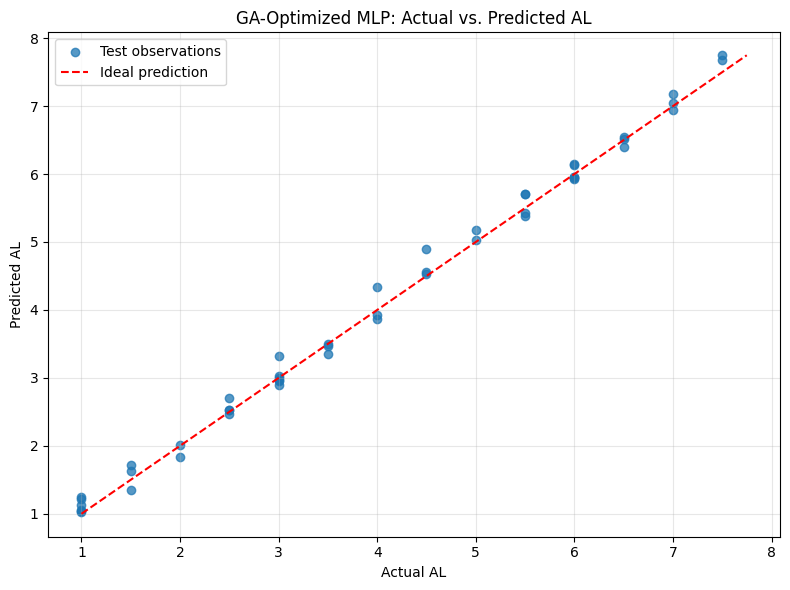

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_mlp,
    alpha=0.75,
    label="Test observations"
)

min_val = min(y_test.min(), y_pred_mlp.min())
max_val = max(y_test.max(), y_pred_mlp.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal prediction"
)

plt.xlabel("Actual AL")
plt.ylabel("Predicted AL")
plt.title("GA-Optimized MLP: Actual vs. Predicted AL")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ANN Regressor

In [19]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

TensorFlow version: 2.20.0
Training samples: 196
Test samples: 50


In [20]:
ann_scaler = StandardScaler()

X_train_ann = ann_scaler.fit_transform(X_train).astype("float32")
X_test_ann = ann_scaler.transform(X_test).astype("float32")

y_train_ann = np.asarray(y_train, dtype="float32")
y_test_ann = np.asarray(y_test, dtype="float32")

print("ANN training input shape:", X_train_ann.shape)
print("ANN test input shape:", X_test_ann.shape)

ANN training input shape: (196, 4)
ANN test input shape: (50, 4)


In [21]:
tf.keras.utils.set_random_seed(42)

ann_model = keras.Sequential([
    keras.Input(shape=(X_train_ann.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="linear")
])

ann_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,433 (9.50 KB)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

start_time = time.perf_counter()

ann_history = ann_model.fit(
    X_train_ann,
    y_train_ann,
    validation_split=0.2,
    epochs=500,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1,
    shuffle=True
)

ann_training_time = time.perf_counter() - start_time

print(f"Training epochs: {len(ann_history.history['loss'])}")
print(f"Training time: {ann_training_time:.2f} seconds")
print(f"Best validation MSE: {min(ann_history.history['val_loss']):.4f}")

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 22.0250 - mean_absolute_error: 4.2733 - val_loss: 17.1751 - val_mean_absolute_error: 3.6949
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 19.5494 - mean_absolute_error: 3.9557 - val_loss: 15.0193 - val_mean_absolute_error: 3.3918
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 17.4158 - mean_absolute_error: 3.6649 - val_loss: 12.8218 - val_mean_absolute_error: 3.0979
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 14.9966 - mean_absolute_error: 3.3219 - val_loss: 10.3793 - val_mean_absolute_error: 2.7346
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 12.3701 - mean_absolute_error: 2.9524 - val_loss: 7.9495 - val_mean_absolute_error: 2.3046
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 9.9779 - mean_absolute_error: 2.6285 - val_loss: 6.1369 - val_mean_absolute_error: 1.9429
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 8.3699 - mean_absolute_error: 2.3914

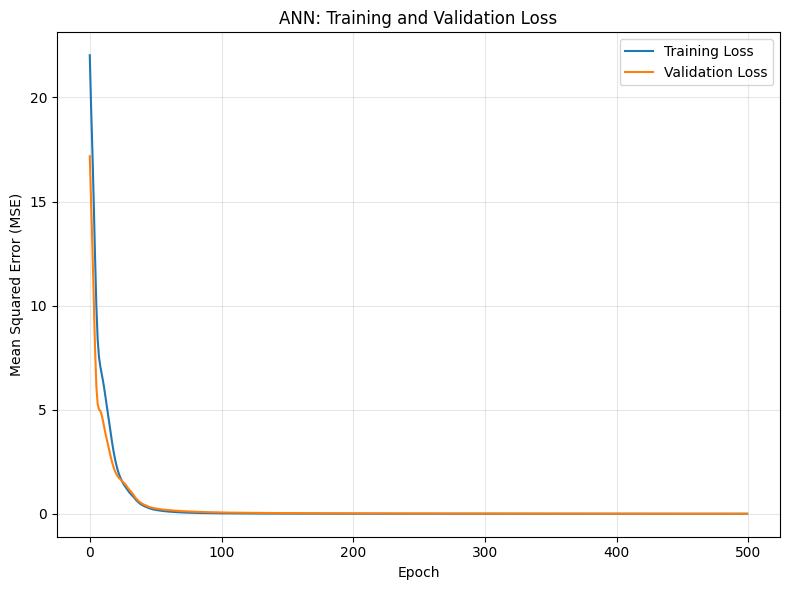

In [23]:
plt.figure(figsize=(8, 6))

plt.plot(
    ann_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    ann_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("ANN: Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
y_pred_ann = ann_model.predict(X_test_ann, verbose=0).flatten()

ann_mae = mean_absolute_error(y_test_ann, y_pred_ann)
ann_mse = mean_squared_error(y_test_ann, y_pred_ann)
ann_rmse = np.sqrt(ann_mse)
ann_r2 = r2_score(y_test_ann, y_pred_ann)
ann_mape = mean_absolute_percentage_error(y_test_ann, y_pred_ann) * 100

print("ANN — Test Results")
print("-" * 40)
print(f"MAE:  {ann_mae:.4f}")
print(f"MSE:  {ann_mse:.4f}")
print(f"RMSE: {ann_rmse:.4f}")
print(f"R²:   {ann_r2:.4f}")
print(f"MAPE: {ann_mape:.2f}%")
print(f"Training time: {ann_training_time:.2f} seconds")

ANN — Test Results
----------------------------------------
MAE:  0.0609
MSE:  0.0061
RMSE: 0.0780
R²:   0.9985
MAPE: 2.24%
Training time: 59.84 seconds


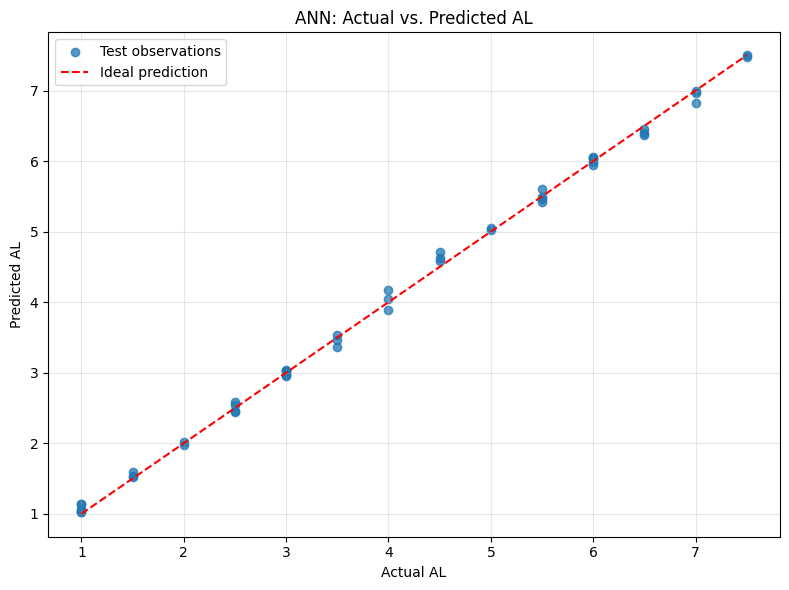

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_ann,
    alpha=0.75,
    label="Test observations"
)

min_val = min(y_test.min(), y_pred_ann.min())
max_val = max(y_test.max(), y_pred_ann.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal prediction"
)

plt.xlabel("Actual AL")
plt.ylabel("Predicted AL")
plt.title("ANN: Actual vs. Predicted AL")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Support Vector Machines

In [26]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import time

svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

param_grid = {
    "svr__C": [0.1, 1, 10, 100, 1000],
    "svr__epsilon": [0.01, 0.1, 0.5, 1.0],
    "svr__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

svr_grid = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

start_time = time.perf_counter()
svr_grid.fit(X_train, y_train)
svr_tuning_time = time.perf_counter() - start_time

print("Best parameters:", svr_grid.best_params_)
print(f"Best CV MAE: {-svr_grid.best_score_:.4f}")
print(f"Tuning time: {svr_tuning_time:.2f} seconds")

Fitting 5 folds for each of 120 candidates, totalling 600 fits
Best parameters: {'svr__C': 1000, 'svr__epsilon': 0.01, 'svr__gamma': 0.1}
Best CV MAE: 0.0317
Tuning time: 2.09 seconds


In [27]:
best_svr = svr_grid.best_estimator_

y_pred_svr_tuned = best_svr.predict(X_test)

svr_tuned_mae = mean_absolute_error(y_test, y_pred_svr_tuned)
svr_tuned_mape = mean_absolute_percentage_error(
    y_test, y_pred_svr_tuned
) * 100
svr_tuned_mse = mean_squared_error(y_test, y_pred_svr_tuned)
svr_tuned_rmse = np.sqrt(svr_tuned_mse)
svr_tuned_r2 = r2_score(y_test, y_pred_svr_tuned)

print("Tuned SVR Test Results")
print("-" * 35)
print(f"MAE:  {svr_tuned_mae:.4f}")
print(f"MAPE: {svr_tuned_mape:.2f}%")
print(f"MSE:  {svr_tuned_mse:.4f}")
print(f"RMSE: {svr_tuned_rmse:.4f}")
print(f"R²:   {svr_tuned_r2:.4f}")

Tuned SVR Test Results
-----------------------------------
MAE:  0.0305
MAPE: 0.87%
MSE:  0.0017
RMSE: 0.0416
R²:   0.9996


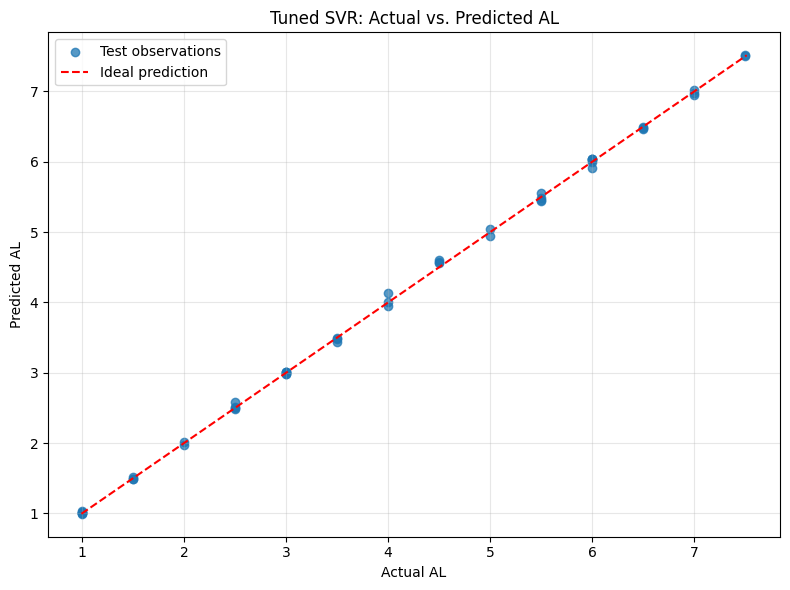

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_svr_tuned,
    alpha=0.75,
    label="Test observations"
)

min_val = min(y_test.min(), y_pred_svr_tuned.min())
max_val = max(y_test.max(), y_pred_svr_tuned.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal prediction"
)

plt.xlabel("Actual AL")
plt.ylabel("Predicted AL")
plt.title("Tuned SVR: Actual vs. Predicted AL")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Random Forest

In [29]:
from sklearn.ensemble import RandomForestRegressor


rf_model = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid_rf = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt"]
}

cv_rf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid_rf,
    scoring="neg_mean_absolute_error",
    cv=cv_rf,
    n_jobs=-1,
    verbose=1
)

start_time = time.perf_counter()

rf_grid.fit(X_train, y_train)

rf_tuning_time = time.perf_counter() - start_time

print("\nBest parameters:", rf_grid.best_params_)
print(f"Best CV MAE: {-rf_grid.best_score_:.4f}")
print(f"Tuning time: {rf_tuning_time:.2f} seconds")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits

Best parameters: {'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}
Best CV MAE: 0.8473
Tuning time: 66.71 seconds


In [30]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)

rf_mae = mean_absolute_error(y_test, y_pred_rf_tuned)
rf_mape = mean_absolute_percentage_error(
    y_test, y_pred_rf_tuned
) * 100
rf_mse = mean_squared_error(y_test, y_pred_rf_tuned)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, y_pred_rf_tuned)

print("Tuned Random Forest Test Results")
print("-" * 40)
print(f"MAE:  {rf_mae:.4f}")
print(f"MAPE: {rf_mape:.2f}%")
print(f"MSE:  {rf_mse:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")

Tuned Random Forest Test Results
----------------------------------------
MAE:  0.7830
MAPE: 34.35%
MSE:  0.8415
RMSE: 0.9173
R²:   0.7921


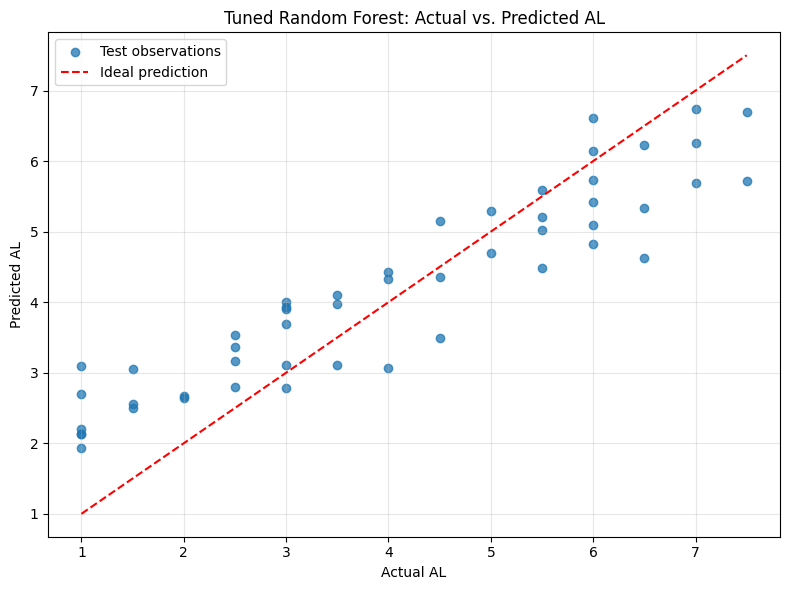

In [31]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf_tuned,
    alpha=0.75,
    label="Test observations"
)

min_val = min(y_test.min(), y_pred_rf_tuned.min())
max_val = max(y_test.max(), y_pred_rf_tuned.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal prediction"
)

plt.xlabel("Actual AL")
plt.ylabel("Predicted AL")
plt.title("Tuned Random Forest: Actual vs. Predicted AL")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()